# 9c. The vortex forecast of the 2026 starts

What do the 1 Feb, 1 May and 1 Aug 2026 starts say about the polar vortex, and how much of it can be checked?

1. **Feb 2026 start against the observed end of winter 2025/26** (the only verifiable part).
2. **Daily U(60°N, 10 hPa) plumes** for 2026/27 and 2027/28, with the model's own climatology.
3. **Vortex index plume** over the whole forecast period: U(60°N), 10-hPa polar-cap temperature and
   height anomaly, polar-cap sea-level pressure.
4. **DJF vortex strength**: drift-corrected anomalies with uncalibrated tercile probabilities, and their
   sensitivity to the climatology method.

**Findings.** The Feb start caught the late-February 2026 weakening 3-4 weeks ahead (about a week early)
but not the reversal. With the direct climatology the DJF 2026/27 anomalies are +1.5 (Feb), +1.1 (May)
and 0.0 m/s (Aug), tercile probabilities near one third each: no predictable vortex anomaly. The
`lead_drift` climatology gave a spurious weak vortex for Feb/Aug (-5 to -7 m/s).

**Read with 9b.** E3SM's DJF vortex is weaker than ERA5's (U(60°N, 10 hPa) about 24 vs 29 m/s, and
about 24 vs 33 m/s in Dec-Jan) and varies far less between winters (σ about 4 vs 10 m/s). Two forecast
winters from one initial state are conditional forecast statistics, not a model climatology.

**The 9a-9i series** (polar vortex and SSWs in the RTENSO2026 2026 starts): `9a` builds and checks the
caches; `9b` model climatology; `9c` vortex forecast; `9d` SSW occurrence; `9e` ENSO/QBO background;
`9f` SSW dynamics; `9g` SSW mechanism (featured member vs controls); `9h` SSW-event animation; `9i`
seasonal-evolution animation. Shared loading: `util/strat_diag.py`; readers `util/strat_case.py`; maps
`util/vortex_plot.py`.

In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from util import rtenso_case as rc
from util import strat_case as sc
from util import strat_diag as sd

warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")

### Run controls

In [2]:
NOTEBOOK = "9c_vortex_forecast"   # outputs: rc.OUTPUT_ROOT/9c_vortex_forecast/{figures,data}/
# "require": read the caches built by 9a only; "auto": build a missing cache; "rebuild": recompute
derivation_mode = "require"
CLIM_METHOD = "direct"      # model climatology: "direct" (each start's Reanalysis starts; Feb/Aug 1985-2010), "lead_drift"
WORKERS = 4                 # processes reading model output (cache builds only; login node: 30 GB per user)

# Data locations (machine-specific)
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                       # reference-data archive
ERA5_ZONAL_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily_zonal"                    # ERA5 daily zonal means
ERA5_DAILY_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily"                          # ERA5 daily maps (PSL)
SIMULATION_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/simulation")         # raw eam.h1 history

cfg = sd.StratConfig(era5_zonal_dir=ERA5_ZONAL_DIR, era5_daily_dir=ERA5_DAILY_DIR, simulation_root=SIMULATION_ROOT,
                     clim_method=CLIM_METHOD, mode=derivation_mode, workers=WORKERS)
YEAR, INIT_MONTHS, POOL, CLIM_YEARS = cfg.year, cfg.init_months, cfg.pool, cfg.clim_years
ERA5_FIRST_YEAR, REF_LEVEL, SSW = cfg.era5_first_year, cfg.ref_level, cfg.ssw
MONTH_NAMES, INIT_COLORS, MODEL_PREFIX = sd.MONTH_NAMES, sd.INIT_COLORS, rc.MODEL_PREFIX
NINO_PRODUCT_OBS = "HadISST1.1"     # observed DJF Nino3.4 (El Nino winters marked)
ENSO_THRESHOLD = 0.5                # degC
DJF = sd.DJF
# Vortex index plume (whole forecast period)
INDEX_SPAN = (f"{YEAR}-01-01", f"{YEAR + 2}-07-31")
SMOOTH_DAYS = 5                     # centred running mean of the daily indices (1: none)
INDEX_RANGE = (0.1, 0.9)            # member quantiles shaded

fontz = 13
fig_type = "png"
fig_dpi = 200
plt.rcParams.update({"font.size": fontz, "axes.titlesize": fontz, "axes.labelsize": fontz,
                     "legend.fontsize": fontz * 0.8, "xtick.labelsize": fontz * 0.85, "ytick.labelsize": fontz * 0.85})
rng = np.random.default_rng(0)


def save(fig, *parts):
    path = rc.save_figure(fig, NOTEBOOK, *parts, dpi=fig_dpi, ext=fig_type)
    print(f"[FIGURE] {path}")


DATA_DIR = rc.output_dir(NOTEBOOK, "data")

### Load

In [3]:
%%time
E = sd.load_era5(cfg)                         # ERA5 daily zonal-mean indices and climatologies (cached)
era5, obs_end = E.fields, E.obs_end
e_u60, e_pcz, e_pct, e_vt, e_qbo, e_pch = E.u60, E.pcz, E.pct, E.vt, E.qbo, E.pch
clim_u60, std_u60, clim_pcz, std_pcz = E.clim_u60, E.std_u60, E.clim_pcz, E.std_pcz
e_month_clim, e_u60_month = E.month_clim, E.u60_month
on_days = sd.on_days

ERA5 daily zonal means 01 Jan 1979 - 30 Jun 2026
CPU times: user 2.81 s, sys: 1.04 s, total: 3.85 s
Wall time: 31.8 s


In [4]:
R = sd.load_references(cfg)                   # Reanalysis monthly zonal means of every start month
ref, ref_direct, REF_ALL, MPLEV = R.ref, R.direct, R.all, R.plev
e_month_clim_m = e_month_clim.sel(plev=MPLEV)   # ERA5 on the model monthly levels

In [5]:
%%time
M = sd.load_model(cfg, E, R)                  # pooled 2026 starts: zonal means, climatologies, daily indices
monthly, daily, lead_clim, z_offset = M.monthly, M.daily, M.lead_clim, M.z_offset
m_u60, m_u60_clim, m_u60_adj, m_pch, m_vt = M.u60, M.u60_clim, M.u60_adj, M.pch, M.vt
mm_u60, mm_u60_anom, mm_qbo = M.mm_u60, M.mm_u60_anom, M.mm_qbo

[init Feb 2026] 20 members, daily 01 Feb 2026 - 31 Jan 2028; climatology: Reanalysis init02 6 starts 1985-2010 (every fifth year)


[init May 2026] 30 members, daily 01 May 2026 - 30 Apr 2028; climatology: Reanalysis init05 1981-2010


[init Aug 2026] 30 members, daily 01 Aug 2026 - 31 Jul 2028; climatology: Reanalysis init08 6 starts 1985-2010 (every fifth year)


[init Nov 2026] 30 members, daily 01 Nov 2026 - 31 Oct 2028; climatology: Reanalysis init11 1981-2010
CPU times: user 3.2 s, sys: 1.69 s, total: 4.9 s
Wall time: 17.3 s


In [6]:
C = sd.ssw_catalogue(cfg, E, M)               # SSW central dates and event properties (raw and bias-adjusted)
obs_events, obs_winters, obs_counts = C.obs_events, C.obs_winters, C.obs_counts
model_ssw, model_ssw_adj, events_all = C.model_ssw, C.model_ssw_adj, C.events
mid_month, case_of, djf_mean, DJF_DAYS = sd.mid_month, sd.case_of, sd.djf_mean, sd.DJF_DAYS

nino_obs, obs_djf_nino = sd.observed_nino(cfg, NINO_PRODUCT_OBS)

### 1. Winter 2025/26 and the 1 Feb 2026 start

Observed daily U(60°N, 10 hPa) from 1 Oct 2025 with the ERA5 1981-2010 daily climatology
(mean ±1σ and ±2σ), the members and ensemble mean of the 1 Feb 2026 start, and the observed and
member final-warming dates (bottom rug). Below: the observed standardized polar-cap height and the Feb
start's ensemble mean over the same days.

ERA5 winter 2025/26: SSW central dates ['28 Nov 2025', '04 Mar 2026']; final warming 24 Mar (censored: ERA5 ends 30 Jun 2026)


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9c_vortex_forecast/figures/fig_winter_20252026_u60n10_pch.png


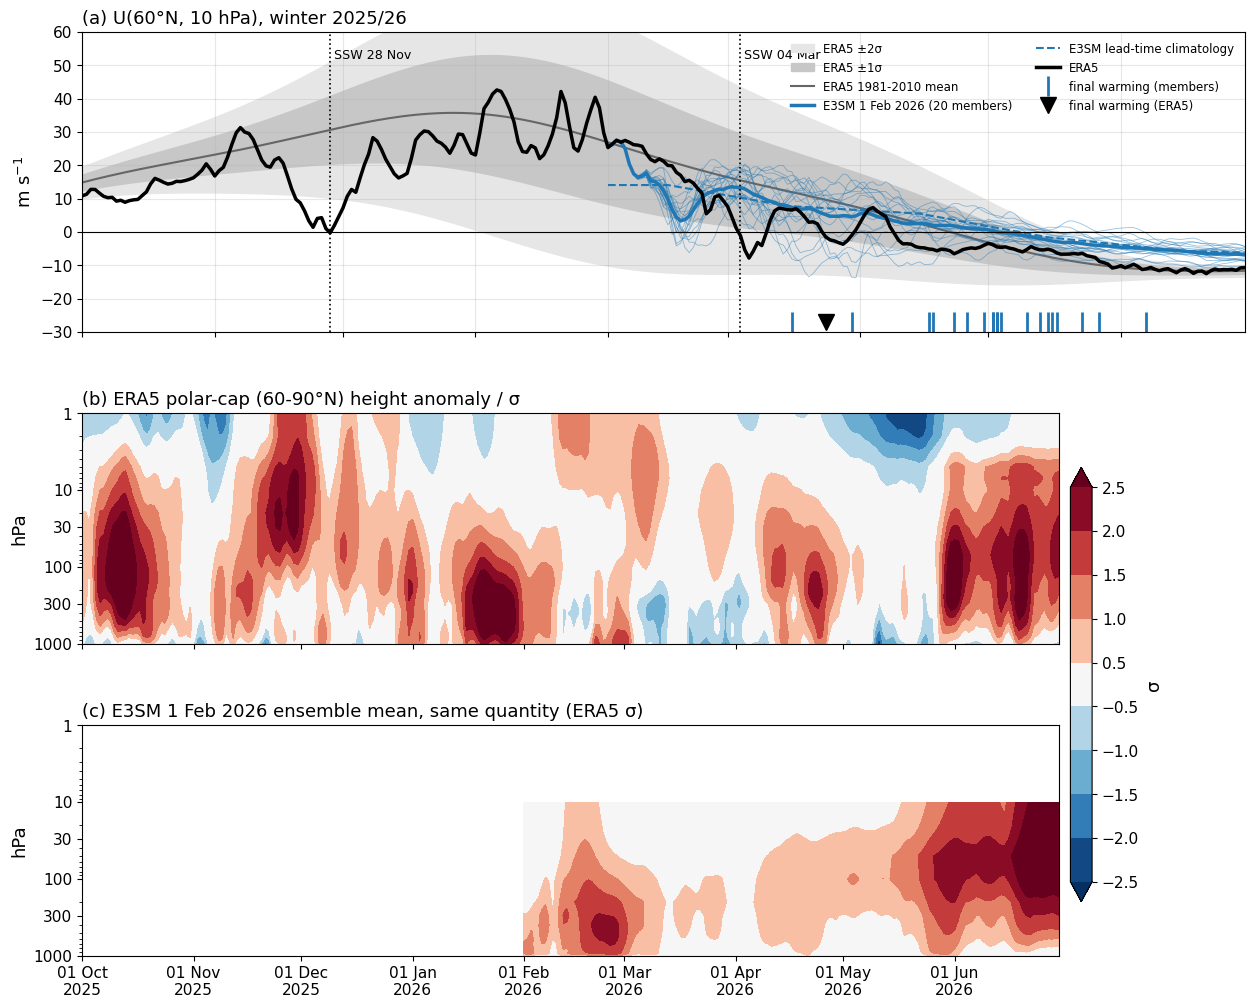

In [7]:
w0 = YEAR - 1
span = (pd.Timestamp(w0, 10, 1), pd.Timestamp(YEAR, 6, 30))
e_obs = e_u60.sel(time=slice(*span))
cl = on_days(clim_u60, e_obs)
sd = on_days(std_u60, e_obs)
obs_ssw_w0 = [d for d in sc.ssw_central_dates(e_u60.values, e_u60["time"].values, **SSW) if sc.winter_of(d) == w0]
obs_fw = {y: sc.final_warming_date(e_u60.values, e_u60["time"].values, y, recover_days=SSW["recover_days"])
          for y in range(ERA5_FIRST_YEAR, obs_end.year + 1)}
fw_date, fw_status = sc.final_warming(e_u60.values, e_u60["time"].values, YEAR, recover_days=SSW["recover_days"])
fw_text = f"{fw_date:%d %b} ({fw_status}: ERA5 ends {obs_end:%d %b %Y})" if pd.notna(fw_date) else f"none yet ({fw_status})"
print(f"ERA5 winter {w0}/{str(YEAR)[2:]}: SSW central dates {[f'{d:%d %b %Y}' for d in obs_ssw_w0] or 'none'}; "
      f"final warming {fw_text}")

init = 2
has_feb = init in INIT_MONTHS
fig, axes = plt.subplots(3 if has_feb else 2, 1, figsize=(15, 12 if has_feb else 8.5),
                         gridspec_kw={"height_ratios": [1.3, 1, 1][: 3 if has_feb else 2], "hspace": 0.32}, sharex=True)
ax = axes[0]
t = e_obs["time"].values
ax.fill_between(t, cl - 2 * sd, cl + 2 * sd, color="0.9", label="ERA5 ±2σ")
ax.fill_between(t, cl - sd, cl + sd, color="0.78", label="ERA5 ±1σ")
ax.plot(t, cl, color="0.4", lw=1.5, label=f"ERA5 {CLIM_YEARS[0]}-{CLIM_YEARS[1]} mean")
if has_feb:
    u = m_u60[init].sel(time=slice(*span))
    for mem in u["member"].values:
        ax.plot(u["time"], u.sel(member=mem), color=INIT_COLORS[init], lw=0.6, alpha=0.45)
    ax.plot(u["time"], u.mean("member"), color=INIT_COLORS[init], lw=2.5, label=f"E3SM 1 Feb {YEAR} ({u.sizes['member']} members)")
    ax.plot(u["time"], m_u60_clim[init].sel(time=slice(*span)), "--", color=INIT_COLORS[init], lw=1.5,
            label="E3SM lead-time climatology")
ax.plot(t, e_obs, "k-", lw=2.5, label="ERA5")
for d in obs_ssw_w0:
    ax.axvline(d, color="k", ls=":", lw=1.2)
    ax.text(d, 55, f" SSW {d:%d %b}", fontsize=fontz * 0.7, va="top")
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("m s$^{-1}$")
ax.set_ylim(-30, 60)
ax.set_title(f"(a) U(60°N, {REF_LEVEL:g} hPa), winter {w0}/{str(YEAR)[2:]}", loc="left")
# final-warming rug
if has_feb:
    fw_m = [sc.final_warming_date(m_u60[init].sel(member=mem).values, m_u60[init]["time"].values, YEAR,
                                  recover_days=SSW["recover_days"]) for mem in m_u60[init]["member"].values]
    fw_m = [d for d in fw_m if pd.notna(d)]
    ax.plot(fw_m, np.full(len(fw_m), -27), "|", color=INIT_COLORS[init], ms=14, mew=2, label="final warming (members)")
if pd.notna(obs_fw.get(YEAR, pd.NaT)):
    ax.plot([obs_fw[YEAR]], [-27], "kv", ms=11, label="final warming (ERA5)")
ax.legend(loc="upper right", ncol=2, fontsize=fontz * 0.65, frameon=False)
ax.grid(alpha=0.3)

pch_lev = np.array([-2.5, -2, -1.5, -1, -0.5, 0.5, 1, 1.5, 2, 2.5])
ep = e_pch.sel(time=slice(*span)).sel(plev=slice(1, 1000))
ax = axes[1]
cf = ax.contourf(ep["time"], ep["plev"], ep.T, levels=pch_lev, cmap="RdBu_r", extend="both")
ax.set_title("(b) ERA5 polar-cap (60-90°N) height anomaly / σ", loc="left")
if has_feb:
    mp = m_pch[init].sel(time=slice(*span)).mean("member")
    ax = axes[2]
    ax.contourf(mp["time"], mp["plev"], mp.T, levels=pch_lev, cmap="RdBu_r", extend="both")
    ax.set_title(f"(c) E3SM 1 Feb {YEAR} ensemble mean, same quantity (ERA5 σ)", loc="left")
for ax in axes[1:]:
    ax.set_yscale("log")
    ax.set_ylim(1000, 1)
    ax.set_yticks([1000, 300, 100, 30, 10, 1], ["1000", "300", "100", "30", "10", "1"])
    ax.set_ylabel("hPa")
axes[-1].set_xlim(*span)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))
fig.colorbar(cf, ax=axes[1:], label="σ", shrink=0.8, pad=0.01)
save(fig, "winter", f"{w0}{YEAR}", "u60n10_pch")
plt.show()

### 2. Daily U(60°N, 10 hPa) plumes, 2026/27 and 2027/28

One row per start: every member's daily U(60°N, 10 hPa) (thin), the ensemble mean (thick), the
model's lead-time climatology (dashed) and ERA5 (climatology band and observations). Dots mark the
SSW central dates on the raw model wind.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9c_vortex_forecast/figures/fig_plume_u60n10_2026.png


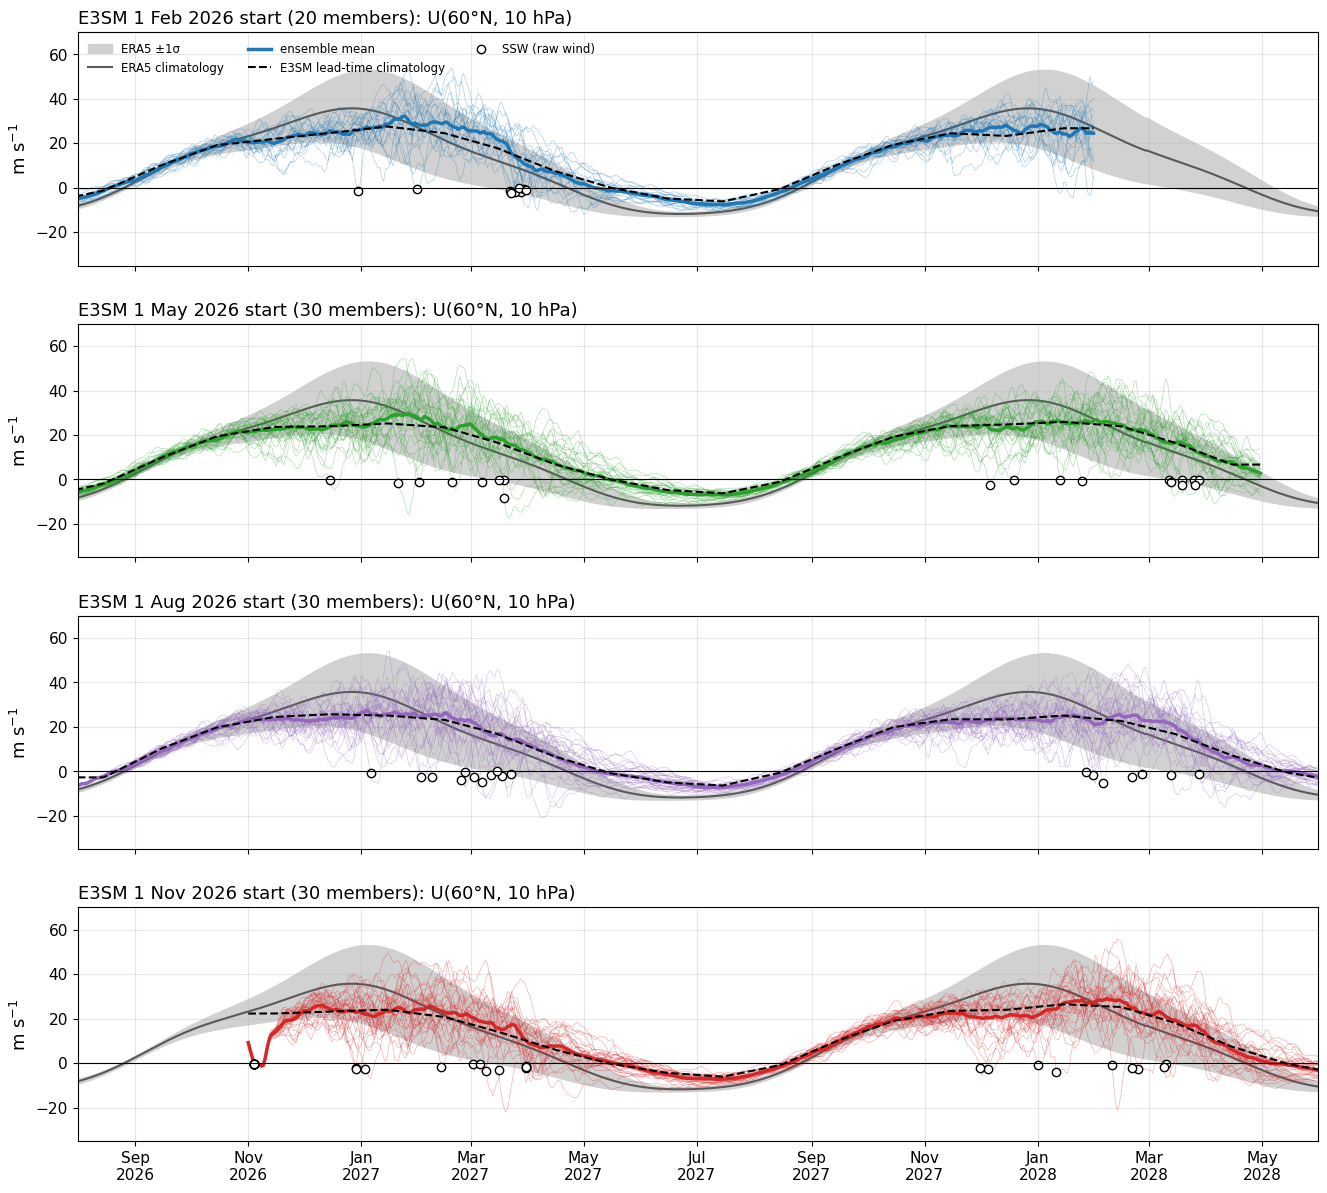

In [8]:
plume_span = (pd.Timestamp(YEAR, 8, 1), pd.Timestamp(YEAR + 2, 5, 31))
fig, axes = plt.subplots(len(INIT_MONTHS), 1, figsize=(16, 3.6 * len(INIT_MONTHS)), sharex=True, sharey=True,
                         gridspec_kw={"hspace": 0.25})
days = pd.date_range(*plume_span, freq="D")
dummy = xr.DataArray(np.zeros(days.size), dims="time", coords={"time": days.values})
cl, sd = on_days(clim_u60, dummy), on_days(std_u60, dummy)
model_ssw = {}                        # init -> DataFrame (series, winter, central_date) on the raw wind
model_ssw_adj = {}                    # bias-adjusted
for ax, init in zip(np.atleast_1d(axes), INIT_MONTHS):
    u = m_u60[init]
    ax.fill_between(days, cl - sd, cl + sd, color="0.82", label="ERA5 ±1σ")
    ax.plot(days, cl, color="0.35", lw=1.5, label="ERA5 climatology")
    for mem in u["member"].values:
        ax.plot(u["time"], u.sel(member=mem), color=INIT_COLORS[init], lw=0.5, alpha=0.35)
    ax.plot(u["time"], u.mean("member"), color=INIT_COLORS[init], lw=2.5, label="ensemble mean")
    ax.plot(u["time"], m_u60_clim[init], "--", color="k", lw=1.5, label="E3SM lead-time climatology")
    e_part = e_u60.sel(time=slice(*plume_span))
    if e_part.sizes["time"]:
        ax.plot(e_part["time"], e_part, "k-", lw=2.5, label="ERA5")
    tabs, tabs_adj = [], []
    for mem in u["member"].values:
        tabs.append(sc.ssw_table(u.sel(member=mem).values, u["time"].values, str(mem), **SSW))
        tabs_adj.append(sc.ssw_table(m_u60_adj[init].sel(member=mem).values, u["time"].values, str(mem), **SSW))
    model_ssw[init] = pd.concat(tabs, ignore_index=True)
    model_ssw_adj[init] = pd.concat(tabs_adj, ignore_index=True)
    ev = model_ssw[init]
    if len(ev):
        y = [float(u.sel(member=s, time=np.datetime64(d)).values) for s, d in zip(ev["series"], ev["central_date"])]
        ax.plot(ev["central_date"], np.asarray(y), "o", ms=6, mfc="w", mec="k", label="SSW (raw wind)")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylim(-35, 70)
    ax.set_ylabel("m s$^{-1}$")
    ax.grid(alpha=0.3)
    ax.set_title(f"E3SM 1 {MONTH_NAMES[init]} {YEAR} start ({u.sizes['member']} members): U(60°N, {REF_LEVEL:g} hPa)", loc="left")
np.atleast_1d(axes)[0].legend(loc="upper left", ncol=3, fontsize=fontz * 0.65, frameon=False)
np.atleast_1d(axes)[-1].set_xlim(*plume_span)
np.atleast_1d(axes)[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
save(fig, "plume", "u60n10", YEAR)
plt.show()

### 3. Vortex index plume

The polar-vortex counterpart of the Niño3.4 plume: daily indices over the whole forecast period,
smoothed with a `SMOOTH_DAYS` running mean. Each start's ensemble mean (thick), its `INDEX_RANGE`
member range (shading) and, for the raw quantities, its own lead-time climatology (dashed: what the
model drifts to), against ERA5 (black) and the ERA5 1981-2010 climatology ±1σ (grey).

* **U(60°N, 10 hPa)**: vortex strength; below zero is an SSW or the final warming. Ticks along
  the bottom are every member's SSW central dates (one row per start) and ERA5's (black).
* **T(60-90°N, 10 hPa)**: the warming of an SSW.
* **Polar-cap (60-90°N) height anomaly at 10 hPa** (m, grey: ERA5 ±1σ; positive is a weak vortex)
  and **sea-level pressure anomaly** (divided by the ERA5 daily standard deviation; the surface
  imprint: positive is a negative NAM). The height is shown in metres because its summer σ is a few
  tens of metres, which would turn the summer trend into several σ. Model anomalies remove the lead-time climatology (notebook 9, `CLIM_METHOD`).
  The native daily Z is ~40 m higher at 10 hPa than the monthly product the climatology is made
  from (online vs post-hoc vertical interpolation; U, T and PSL agree), so each run's ensemble-mean
  daily-minus-monthly offset is added to the climatology (`sc.daily_monthly_offset`).
  The Feb and Aug starts have no Reanalysis climatology; their `lead_drift` climatology borrows the
  mean May/Nov drift, which is poor at 10 hPa in the first summer months (the Aug start's lead-0 jump).

In [9]:
%%time
LEVS = [10.0]


def vortex_indices(ds):
    return {"u60": sc.lat_mean(ds["U"].sel(plev=10.0), sc.U60),
            "t10": sc.lat_mean(ds["T"].sel(plev=10.0), sc.PCAP),
            "z10": sc.lat_mean(ds["Z"].sel(plev=10.0), sc.PCAP)}


def on_doy(clim, times):
    d = xr.DataArray(sc.noleap_doy(times), dims="time", coords={"time": times})
    return clim.sel(doy=d).drop_vars("doy")


# ERA5 indices and their smoothed daily climatologies (mean, std)
era5_z = sc.era5_daily_zonal(ERA5_ZONAL_DIR, fields=("U", "T", "Z"), plev=LEVS)
e_idx = vortex_indices(era5_z)
e_idx["slp"] = sc.era5_polar_cap_slp(ERA5_DAILY_DIR, years=(ERA5_FIRST_YEAR, YEAR))
e_iclim = {k: sc.daily_climatology(v, CLIM_YEARS) for k, v in e_idx.items()}

# model indices: raw, the lead-time climatology on the same days, and the anomaly
ref = {m: sc.monthly_zonal(rc.REFERENCE["case_prefix"], "Reanalysis", range(CLIM_YEARS[0], CLIM_YEARS[1] + 1), m,
                           mode=derivation_mode, workers=WORKERS).sel(plev=LEVS)
       for m in rc.REFERENCE["init_months"]}
ref_direct = {m: sc.monthly_zonal(rc.REFERENCE["case_prefix"], "Reanalysis", range(CLIM_YEARS[0], CLIM_YEARS[1] + 1), m,
                                  mode=derivation_mode, workers=WORKERS).sel(plev=LEVS)
              for m in rc.DIRECT_INIT_MONTHS}      # Feb/Aug starts of every fifth year (1985-2010)
REF_ALL = {**ref, **ref_direct}
e_month = sc.obs_month_climatology(era5_z[["U", "T", "Z"]], CLIM_YEARS)
m_idx = {}
for init in INIT_MONTHS:
    zd = sc.pooled_daily_zonal(SIMULATION_ROOT, POOL, YEAR, init, mode=derivation_mode, workers=WORKERS)
    if zd is None:
        continue
    # daily (native) Z differs from the monthly product by a near-constant offset: add it to the climatology
    mo = sc.pooled_monthly_zonal(POOL, YEAR, init, mode=derivation_mode, workers=WORKERS)
    z_off = sc.daily_monthly_offset(zd, mo, YEAR, init).sel(plev=LEVS)
    zd = zd.sel(plev=LEVS)
    lc = sc.lead_climatology(init, REF_ALL if CLIM_METHOD == "direct" else ref, e_month, method=CLIM_METHOD)
    lc["Z"] = lc["Z"] + z_off
    cd = sc.daily_from_lead(lc, YEAR, init, zd["time"].values).assign_coords(time=zd["time"])
    raw, clim = vortex_indices(zd), vortex_indices(cd)
    # surface: polar-cap sea-level pressure against the drift-corrected PSL climatology (rtenso_case)
    psl_clim = sc.lat_mean(rc.matched_climatology("PSL", init, method=CLIM_METHOD, mode=derivation_mode).mean("lon"), sc.PCAP)
    raw["slp"] = sc.lat_mean(zd["PSL"], sc.PCAP)
    clim["slp"] = sc.daily_from_lead(psl_clim, YEAR, init, zd["time"].values).assign_coords(time=zd["time"])
    alt = None
    ALT = "lead_drift" if CLIM_METHOD == "direct" else "target_month"
    if init not in ref:                       # Feb/Aug: the climatology method matters; show the alternative
        lc_alt = sc.lead_climatology(init, ref, e_month, method=ALT)
        lc_alt["Z"] = lc_alt["Z"] + z_off
        clim_alt = vortex_indices(sc.daily_from_lead(lc_alt, YEAR, init, zd["time"].values).assign_coords(time=zd["time"]))
        pc_alt = sc.lat_mean(rc.matched_climatology("PSL", init, method=ALT, mode=derivation_mode).mean("lon"), sc.PCAP)
        clim_alt["slp"] = sc.daily_from_lead(pc_alt, YEAR, init, zd["time"].values).assign_coords(time=zd["time"])
        alt = {k: raw[k] - clim_alt[k] for k in ("z10", "slp")}
    m_idx[init] = {"raw": raw, "clim": clim, "anom": {k: raw[k] - clim[k] for k in raw}, "anom_alt": alt,
                   "ssw": [d for mem in raw["u60"]["member"].values
                           for d in sc.ssw_central_dates(raw["u60"].sel(member=mem).values, raw["u60"]["time"].values, **SSW)]}
obs_ssw = sc.ssw_central_dates(e_idx["u60"].values, e_idx["u60"]["time"].values, **SSW)

[Reanalysis-OBS 2026-02] repeats an already pooled case member for member; not pooled again


CPU times: user 2min 2s, sys: 14.2 s, total: 2min 16s
Wall time: 4min 23s


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9c_vortex_forecast/figures/fig_rtenso2026_y2026_vortex_indices_plume.png


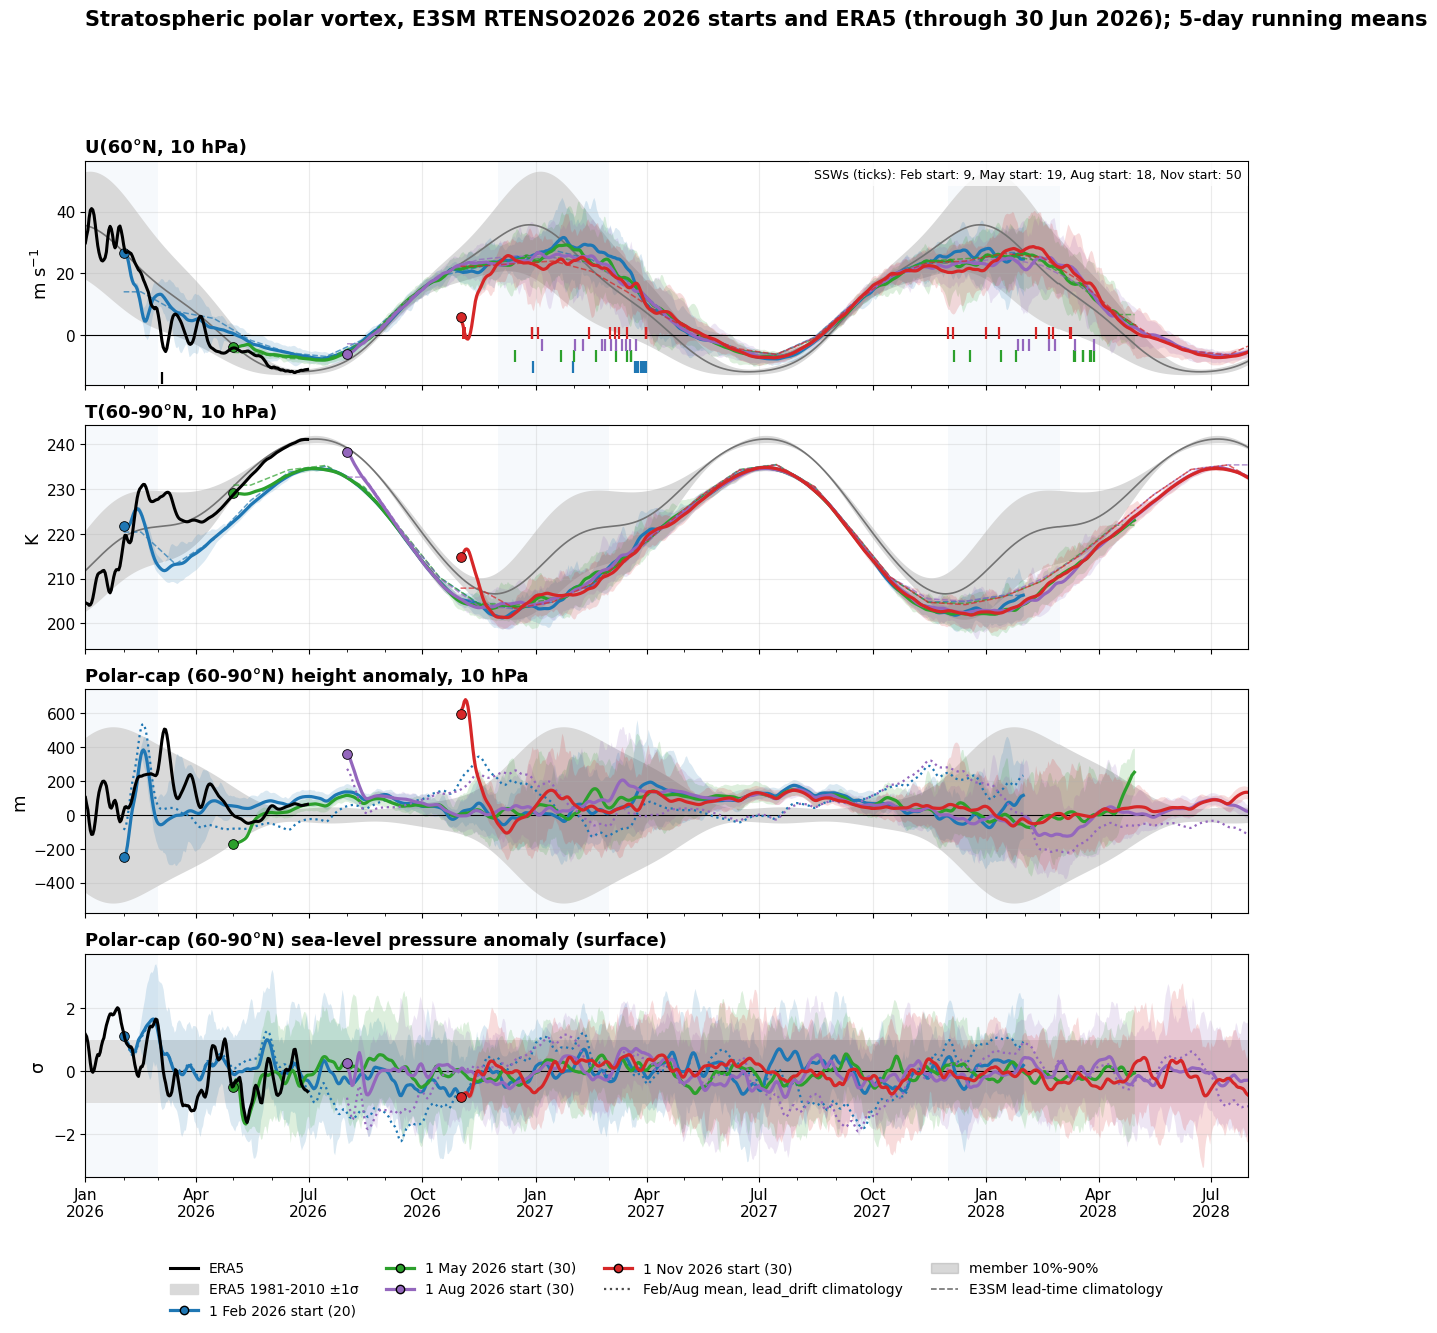

In [10]:
PANELS = [("u60", "raw", "U(60°N, 10 hPa)", "m s$^{-1}$"),
          ("t10", "raw", "T(60-90°N, 10 hPa)", "K"),
          ("z10", "anom", "Polar-cap (60-90°N) height anomaly, 10 hPa", "m"),
          ("slp", "std", "Polar-cap (60-90°N) sea-level pressure anomaly (surface)", "σ")]
span = slice(*INDEX_SPAN)
span_days = pd.date_range(*INDEX_SPAN, freq="D").values


def smooth(da):
    return da.rolling(time=SMOOTH_DAYS, center=True, min_periods=1).mean() if SMOOTH_DAYS > 1 else da


fig, axes = plt.subplots(len(PANELS), 1, figsize=(15, 3.3 * len(PANELS)), sharex=True, gridspec_kw={"hspace": 0.18})
for ax, (key, kind, title, units) in zip(axes, PANELS):
    mean, std = e_iclim[key]
    # winters (DJF) shaded lightly
    for y in range(pd.Timestamp(INDEX_SPAN[0]).year - 1, pd.Timestamp(INDEX_SPAN[1]).year + 1):
        ax.axvspan(np.datetime64(f"{y}-12-01"), np.datetime64(f"{y + 1}-03-01"), color="tab:blue", alpha=0.04, lw=0)
    if kind == "raw":
        c, sd = on_doy(mean, span_days), on_doy(std, span_days)
        ax.fill_between(span_days, c - sd, c + sd, color="0.85", lw=0)
        ax.plot(span_days, c, color="0.45", lw=1.2)
    elif kind == "anom":
        sd = on_doy(std, span_days)
        ax.fill_between(span_days, -sd, sd, color="0.85", lw=0)
    else:
        ax.axhspan(-1, 1, color="0.88", lw=0)
    if key == "u60" or kind != "raw":
        ax.axhline(0, color="k", lw=0.8)
    for init, m in m_idx.items():
        color = INIT_COLORS[init]
        s = m["raw" if kind == "raw" else "anom"][key]
        if kind == "std":
            s = s / on_doy(std, s["time"].values)
        s = smooth(s).sel(time=span)
        if not s.sizes["time"]:
            continue
        t = s["time"].values
        q = s.quantile(list(INDEX_RANGE), "member")
        ax.fill_between(t, q.isel(quantile=0), q.isel(quantile=1), color=color, alpha=0.16, lw=0)
        ens = s.mean("member")
        ax.plot(t, ens, color=color, lw=2.3)
        ax.plot(t[0], float(ens[0]), "o", color=color, ms=7, mec="k", mew=0.6, zorder=5)
        if kind == "raw":
            ax.plot(t, m["clim"][key].sel(time=span), color=color, lw=1.1, ls="--", alpha=0.7)
        elif m["anom_alt"] is not None and key in m["anom_alt"]:
            a = m["anom_alt"][key]
            if kind == "std":
                a = a / on_doy(std, a["time"].values)
            ax.plot(t, smooth(a).sel(time=span).mean("member"), color=color, lw=1.6, ls=":")
    o = e_idx[key].sel(time=span)
    if o.sizes["time"]:
        if kind != "raw":
            o = o - on_doy(mean, o["time"].values)
        if kind == "std":
            o = o / on_doy(std, o["time"].values)
        ax.plot(o["time"].values, smooth(o), color="k", lw=2.2, zorder=6)
    ax.set_ylabel(units)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(alpha=0.25)

# SSW central dates: one row of ticks per start, ERA5 in black
ax = axes[0]
rows = [("ERA5", "k", [d for d in obs_ssw if pd.Timestamp(INDEX_SPAN[0]) <= d <= pd.Timestamp(INDEX_SPAN[1])])]
rows += [(f"{MONTH_NAMES[i]} start", INIT_COLORS[i], m["ssw"]) for i, m in m_idx.items()]
for k, (label, color, dates) in enumerate(rows):
    y = 0.03 + 0.05 * k
    ax.plot(dates, np.full(len(dates), y), "|", color=color, ms=9, mew=1.6, transform=ax.get_xaxis_transform(), zorder=7)
n_ssw = ", ".join(f"{label}: {len(d)}" for label, _, d in rows[1:])
ax.text(0.995, 0.97, f"SSWs (ticks): {n_ssw}", transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8})

axes[-1].set_xlim(np.datetime64(INDEX_SPAN[0]), np.datetime64(INDEX_SPAN[1]))
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 4, 7, 10)))
axes[-1].xaxis.set_minor_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
handles = [Line2D([], [], color="k", lw=2.2, label="ERA5"),
           Patch(color="0.85", label=f"ERA5 {CLIM_YEARS[0]}-{CLIM_YEARS[1]} ±1σ")]
handles += [Line2D([], [], color=INIT_COLORS[i], lw=2.3, marker="o", mec="k", ms=6,
                   label=f"1 {MONTH_NAMES[i]} {YEAR} start ({m_idx[i]['raw']['u60'].sizes['member']})") for i in m_idx]
handles += [Line2D([], [], color="0.3", lw=1.6, ls=":", label=f"Feb/Aug mean, {'lead_drift' if CLIM_METHOD == 'direct' else 'target_month'} climatology"),
            Patch(color="0.5", alpha=0.3, label=f"member {INDEX_RANGE[0]:.0%}-{INDEX_RANGE[1]:.0%}"),
            Line2D([], [], color="0.4", lw=1.1, ls="--", label="E3SM lead-time climatology")]
axes[-1].legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=4, frameon=False, fontsize=10)
fig.suptitle(f"Stratospheric polar vortex, E3SM RTENSO2026 {YEAR} starts and ERA5 (through {obs_end:%d %b %Y}); "
             f"{SMOOTH_DAYS}-day running means", x=0.125, ha="left", y=0.995, fontsize=15, fontweight="bold")
print(rc.save_figure(fig, NOTEBOOK, "RTENSO2026", f"y{YEAR}", "vortex_indices", "plume", dpi=fig_dpi))
plt.show()

### 4. DJF vortex strength

**DJF vortex strength.** Drift-corrected, day-weighted DJF-mean U(60°N, 10 hPa) anomalies of every
member (monthly output, the product the drift climatology is made from), with **uncalibrated ensemble
tercile probabilities**: there is no hindcast verification of these probabilities.

* **Tercile bounds** are matched to the start and lead: the Reanalysis starts of the same month at
  the same leads (May: 1981-2010, 300 member-winters; Feb and Aug: the starts of every fifth year,
  1985-2010, 60 member-winters).
* **Climatology** (`CLIM_METHOD = "direct"`): each start's own Reanalysis climatology. For Feb and Aug it
  comes from the six 1985-2010 starts and needs no drift assumption. The table compares it with the
  earlier `lead_drift` (ERA5 target-month climatology plus the mean May/Nov drift), `target_month`, and
  May-only or Nov-only drift. These alternatives gave Feb/Aug anomalies of opposite signs (a
  spurious weak vortex under `lead_drift`); the direct climatology puts all three starts near normal.
* ERA5 DJF anomalies (1979/80 on, against the 1981-2010 calendar-month climatology) are shown for
  reference, with El Niño winters marked.

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9c_vortex_forecast/data/djf_vortex_terciles_2026.csv; ERA5 tercile bounds -5.1 / +6.7 m/s
ERA5 El Niño winters: weak 38%, strong 25% (16 winters)
Uncalibrated ensemble tercile probabilities (direct climatology marks the plotted anomalies; Feb/Aug rows compare the climatology methods):


,start,winter,climatology,members,mean anomaly (m/s),P(weak),P(normal),P(strong),bounds
0,Feb,2026/27,direct,20,1.52,0.35,0.20,0.45,-1.1 / +1.4 (matched (Feb/Aug starts every fif...
1,Feb,2026/27,lead_drift,20,-4.62,0.80,0.15,0.05,-1.1 / +1.4 (matched (Feb/Aug starts every fif...
2,Feb,2026/27,target_month,20,2.38,0.25,0.20,0.55,-1.1 / +1.4 (matched (Feb/Aug starts every fif...
3,Feb,2026/27,"lead_drift, May drift only",20,-7.66,1.00,0.00,0.00,-1.1 / +1.4 (matched (Feb/Aug starts every fif...
4,Feb,2026/27,"lead_drift, Nov drift only",20,-1.58,0.55,0.15,0.30,-1.1 / +1.4 (matched (Feb/Aug starts every fif...
5,May,2026/27,direct,30,1.06,0.20,0.33,0.47,"-1.8 / +1.6 (matched, n=300)"
6,May,2027/28,direct,30,-0.50,0.37,0.37,0.27,"-1.8 / +1.7 (matched, n=300)"
7,Aug,2026/27,direct,30,-0.02,0.40,0.30,0.30,-1.3 / +2.2 (matched (Feb/Aug starts every fif...
8,Aug,2026/27,lead_drift,30,-6.50,0.93,0.07,0.00,-1.3 / +2.2 (matched (Feb/Aug starts every fif...
9,Aug,2026/27,target_month,30,1.19,0.27,0.30,0.43,-1.3 / +2.2 (matched (Feb/Aug starts every fif...


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9c_vortex_forecast/figures/fig_djf_vortex_terciles_2026.png


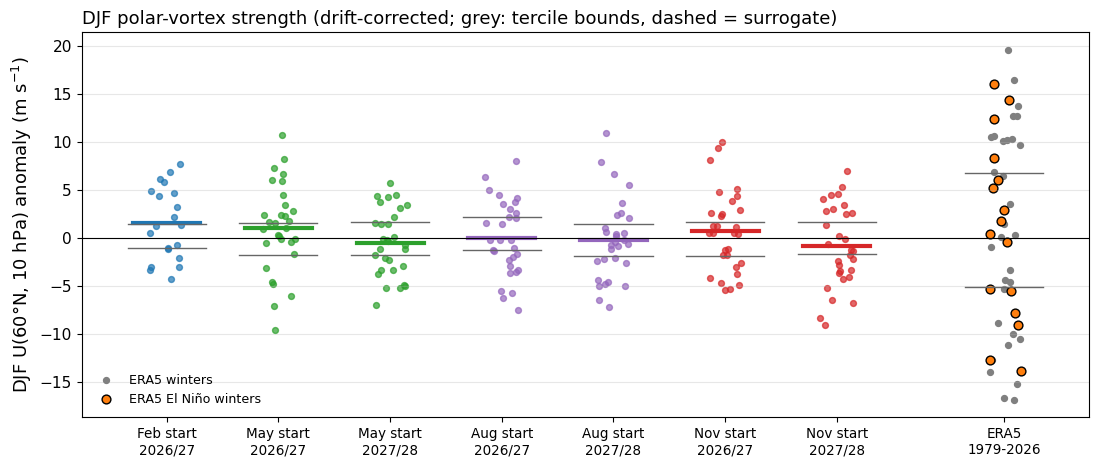

In [11]:
DJF_DAYS = np.array([31.0, 31.0, 28.0])          # day weights of Dec, Jan, Feb (no-leap model calendar)


def djf_mean(series, w):
    # day-weighted DJF mean of a monthly series stamped on the 15th; NaN unless all three months exist
    times = [np.datetime64(f"{w + dy}-{m:02d}-15") for dy, m in DJF]
    if not all(t in series["time"].values for t in times):
        return None
    v = series.sel(time=times)
    return (v * xr.DataArray(DJF_DAYS, dims="time", coords={"time": v["time"]})).sum("time") / DJF_DAYS.sum()


def djf_leads(start_month, k):
    # leads of Dec, Jan, Feb of the k-th winter after a start month
    dec = (12 - start_month) % 12 + 12 * k
    return [dec, dec + 1, dec + 2]


def ref_djf_anomalies(m, k):
    # Reanalysis DJF anomalies (year, member) of start month m in its k-th winter, about the mean over years and members
    leads = djf_leads(m, k)
    if leads[-1] >= REF_ALL[m].sizes["lead"]:
        return None
    u = sc.lat_mean(REF_ALL[m]["U"].sel(plev=REF_LEVEL), sc.U60).isel(lead=leads)
    # skipna=False: years without a start (Feb/Aug: all but every fifth year) stay NaN, not zero
    u = (u * xr.DataArray(DJF_DAYS, dims="lead", coords={"lead": u["lead"]})).sum("lead", skipna=False) / DJF_DAYS.sum()
    return (u - u.mean()).values.ravel()


def tercile_bounds(init, k):
    # (lo, hi, kind): matched to the start and lead when the Reanalysis has the start month, else a surrogate
    if init in REF_ALL:
        a, kind = ref_djf_anomalies(init, k), "matched" if init in ref else "matched (Feb/Aug starts every fifth year)"
    else:
        parts = [ref_djf_anomalies(m, k) for m in ref]
        a, kind = np.concatenate([p for p in parts if p is not None]), "surrogate (May+Nov pooled)"
    a = a[np.isfinite(a)]
    return *np.percentile(a, [100 / 3, 200 / 3]), kind, a.size


# observed DJF anomalies: calendar-month climatology subtracted month by month
era5_month_clim = e_u60_month.sel(time=slice(f"{CLIM_YEARS[0]}-01-01", f"{CLIM_YEARS[1]}-12-31")).groupby("time.month").mean("time")
e_anom_month = (e_u60_month.groupby("time.month") - era5_month_clim).drop_vars("month")
assert e_anom_month.dims == ("time",), e_anom_month.dims
e_djf = pd.Series({w: float(v) for w in range(ERA5_FIRST_YEAR, YEAR) if (v := djf_mean(e_anom_month, w)) is not None}).dropna()
e_lo, e_hi = np.percentile(e_djf.values, [100 / 3, 200 / 3])

# drift-correction alternatives for the DJF climatology (Feb/Aug); the May climatology is direct
CLIM_VARIANTS = {"direct": ("direct", list(REF_ALL)), "lead_drift": ("lead_drift", list(ref)),
                 "target_month": ("target_month", list(ref)),
                 "lead_drift, May drift only": ("lead_drift", [5]), "lead_drift, Nov drift only": ("lead_drift", [11])}

m_djf, prob_rows = {}, []
for init in INIT_MONTHS:
    raw = mm_u60[init].assign_coords(time=monthly[init]["time"]).swap_dims(lead="time")
    for k, w in enumerate((YEAR, YEAR + 1)):
        v_raw = djf_mean(raw, w)
        if v_raw is None:
            continue
        lo, hi, kind, n_ref = tercile_bounds(init, k)
        for name, (method, refs) in CLIM_VARIANTS.items():
            if init in ref and name != "direct":
                continue                                           # May/Nov: every method is the direct climatology
            lc = sc.lead_climatology(init, {m: REF_ALL[m] for m in refs}, e_month_clim_m, method=method)
            clim = sc.lat_mean(lc["U"].sel(plev=REF_LEVEL), sc.U60).assign_coords(time=("lead", monthly[init]["time"].values))
            v = v_raw - djf_mean(clim.swap_dims(lead="time"), w)
            if name == CLIM_METHOD:
                m_djf[(init, w)] = v
            prob_rows.append({"start": MONTH_NAMES[init], "winter": f"{w}/{str(w + 1)[2:]}", "climatology": name,
                              "members": int(v.size), "mean anomaly (m/s)": float(v.mean()),
                              "P(weak)": float((v < lo).mean()), "P(normal)": float(((v >= lo) & (v <= hi)).mean()),
                              "P(strong)": float((v > hi).mean()), "bounds": f"{lo:+.1f} / {hi:+.1f} ({kind}, n={n_ref})"})
probs = pd.DataFrame(prob_rows)
probs.to_csv(DATA_DIR / f"djf_vortex_terciles_{YEAR}.csv", index=False)
print(f"[WRITE] {DATA_DIR / f'djf_vortex_terciles_{YEAR}.csv'}; ERA5 tercile bounds {e_lo:+.1f} / {e_hi:+.1f} m/s")
nino_years = [w for w in e_djf.index if obs_djf_nino.get(w, np.nan) >= ENSO_THRESHOLD]
print(f"ERA5 El Niño winters: weak {np.mean(e_djf[nino_years] < e_lo):.0%}, strong {np.mean(e_djf[nino_years] > e_hi):.0%} "
      f"({len(nino_years)} winters)")
print(f"Uncalibrated ensemble tercile probabilities ({CLIM_METHOD} climatology marks the plotted anomalies; Feb/Aug rows compare the climatology methods):")
display(probs.round(2))

fig, ax = plt.subplots(figsize=(13, 5))
pos, labels = [], []
for k, ((init, w), v) in enumerate(m_djf.items()):
    xs = np.full(v.size, k) + rng.uniform(-0.15, 0.15, v.size)
    ax.scatter(xs, v.values, color=INIT_COLORS[init], s=18, alpha=0.7)
    ax.plot([k - 0.3, k + 0.3], [float(v.mean())] * 2, color=INIT_COLORS[init], lw=3)
    lo, hi, kind, _ = tercile_bounds(init, w - YEAR)
    ax.plot([k - 0.35, k + 0.35], [lo, lo], color="0.4", lw=1, ls="--" if kind.startswith("surrogate") else "-")
    ax.plot([k - 0.35, k + 0.35], [hi, hi], color="0.4", lw=1, ls="--" if kind.startswith("surrogate") else "-")
    pos.append(k)
    labels.append(f"{MONTH_NAMES[init]} start\n{w}/{str(w + 1)[2:]}")
k0 = len(pos) + 0.5
xs = np.full(e_djf.size, k0) + rng.uniform(-0.15, 0.15, e_djf.size)
nino_mask = np.array([w in nino_years for w in e_djf.index])
ax.scatter(xs[~nino_mask], e_djf.values[~nino_mask], color="0.5", s=18, label="ERA5 winters")
ax.scatter(xs[nino_mask], e_djf.values[nino_mask], color="tab:orange", edgecolor="k", s=40, label="ERA5 El Niño winters")
ax.plot([k0 - 0.35, k0 + 0.35], [e_lo, e_lo], color="0.4", lw=1)
ax.plot([k0 - 0.35, k0 + 0.35], [e_hi, e_hi], color="0.4", lw=1)
pos.append(k0)
labels.append(f"ERA5\n{int(e_djf.index[0])}-{int(e_djf.index[-1]) + 1}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(pos, labels, fontsize=fontz * 0.75)
ax.set_ylabel("DJF U(60°N, 10 hPa) anomaly (m s$^{-1}$)")
ax.set_title("DJF polar-vortex strength (drift-corrected; grey: tercile bounds, dashed = surrogate)", loc="left")
ax.legend(frameon=False, loc="lower left", fontsize=fontz * 0.7)
ax.grid(alpha=0.3, axis="y")
save(fig, "djf", "vortex", "terciles", YEAR)
plt.show()